# Developing NWA12 Supergrid, Land Mask, and Topo 

In [ ]:
# Functional Packages
import xarray as xr 
import numpy as np  

from scipy.spatial import cKDTree

from datetime import datetime

# Visualization Packages
import matplotlib as mpl
import matplotlib.pyplot as plt

import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [ ]:
# Create output folders 

def make_dir(dir_str):
    if not os.path.exists(dir_str):
        os.makedirs(dir_str)
        print("new directory created: "+ dir_str)

make_dir("input_files")
make_dir("plots")

## Define Helpful Grid Functions

In [ ]:
def spherical2cartesian(lon, lat):
    '''
    Convert spherical coordinates to cartesian coordinates 
    '''
    R_earth=6378136 # meters
    lonr = np.deg2rad(lon)
    latr = np.deg2rad(lat)
    x = R_earth * np.cos(latr) * np.cos(lonr)
    y = R_earth * np.cos(latr) * np.sin(lonr)
    z = R_earth * np.sin(latr)
    return x, y, z

In [ ]:
def create_tree(lon, lat):
    '''
    Create a K-d tree from the spherical coordinates, which is good for spatial queries, like nearest neighbor search
    '''
    # Cnvert spherical coordinates to cartesian coordinates
    x, y, z = spherical2cartesian(lon, lat)

    # Stack - flatten the cartesian coordinates in 1D arrays
    x_stack = x.stack(points=x.dims).values
    y_stack = y.stack(points=y.dims).values
    z_stack = z.stack(points=z.dims).values

    # Construct KD-tree
    tree = cKDTree(np.column_stack((x_stack, y_stack, z_stack)))

    # Return tree
    return tree

In [2]:
def find_nearest(lon, lat, lon_pt, lat_pt):
    '''
    Find the nearest point to lon_pt, lat_pt in the grid defined by lon, lat
    '''

    tree = create_tree(lon, lat)
    xp, yp, zp = spherical2cartesian(lon_pt, lat_pt)
    _, idx = tree.query(np.column_stack((xp, yp, zp)))
    
    #idx = np.unique(idx) # Remove duplicates

    idx = np.unravel_index(idx, lon.shape)
    Iidx = idx[1]
    Jidx = idx[0]

    return Iidx, Jidx

### Find the extent of the GFDL NWA12 Grid

In [ ]:
# Read in GFDL NWA12 Grid

ds = xr.open_dataset('/glade/work/gmarques/Projects/NWA12/grid/ocean_hgrid.nc')

In [ ]:
# Find the extent of the grid in the longitude

lon_min = np.floor(ds.x.min())
lon_max = np.ceil(ds.x.max())

In [ ]:
# Find the extent of the grid in the latitude

lat_min = np.floor(ds.y.min())
lat_max = np.ceil(ds.y.max())

## Read in OS's MOM6 global 1/12 degree supergrid and topo/mask (on modelgrid)

In [ ]:
# Reed in Global Supergrid

dsg = xr.open_dataset('/glade/work/fredc/cesm/grid/MOM6/tx1_12v1/gridgen/ocean_hgrid_trimmed.nc')

In [ ]:
# Read in Global Topography and Mask

dsg_topo = xr.open_dataset('/glade/work/bryan/MOM6-data-files/Topography/tx1_12v1/topo.sub25.tx1_12v1.srtm.edit1.SmL1.0_C1.0.nc')

## Find indices in the global grid that most closely match the extent of the GFDL NWA12 grid

In [ ]:
I_llc, J_llc = find_nearest(dsg.x, dsg.y, lon_min, lat_min)


In [ ]:
I_urc, J_urc =  find_nearest(dsg.x, dsg.y, lon_max, lat_max)


In [3]:
print("LLC:",I_llc, J_llc)
print("URC:",I_urc, J_urc)

NameError: name 'I_llc' is not defined

## Manually select grid extent for a final grid size that plays well with MPI

In [ ]:
I_llc = 4536
J_llc = 3484

In [ ]:
I_urc = 6016
J_urc = 5044

## Cut grid to manual extent and save supergrid file

In [ ]:
# Cut grid

ds_nwa = dsg.isel(nx=slice(I_llc,I_urc)).isel(ny=slice(J_llc,J_urc))

In [ ]:
# Cut grid

ds_nwa = ds_nwa.isel(nxp=slice(I_llc,I_urc+1)).isel(nyp=slice(J_llc,J_urc+1))

In [ ]:
# Add metadata

ds_nwa = ds_nwa.assign_attrs({'Description':'MOM6 NCAR NWA12', 'Created':datetime.now().isoformat()})

In [ ]:
# Show grid file locally

print(ds_nwa)

<xarray.Dataset> Size: 111MB
Dimensions:   (nyp: 1561, nxp: 1481, ny: 1560, nx: 1480)
Dimensions without coordinates: nyp, nxp, ny, nx
Data variables:
    tile      |S255 255B ...
    y         (nyp, nxp) float64 18MB 5.201 5.201 5.201 ... 58.37 58.37 58.38
    x         (nyp, nxp) float64 18MB -98.0 -97.96 -97.92 ... -37.49 -37.45
    dy        (ny, nxp) float64 18MB ...
    dx        (nyp, nx) float64 18MB ...
    area      (ny, nx) float64 18MB ...
    angle_dx  (nyp, nxp) float64 18MB ...
Attributes:
    file_name:    ocean_hgrid.nc
    Description:  MOM6 NCAR NWA12
    Author:       Fred Castruccio (fredc@ucar.edu)
    Created:      2024-09-03T11:50:54.207265
    type:         MOM6 supergrid file

In [ ]:
# Save grid file locally

ds_nwa.to_netcdf('input_files/ocean_hgrid.nc')

## Create regional Mask and Topo files

In [ ]:
# Mask and Topo files are on the model grid, which is a division of 2 of the supergrid in each dimension

i1 = I_llc // 2
j1 = J_llc // 2

nx = (I_urc - I_llc) // 2
ny = (J_urc - J_llc) // 2

i2 = i1 + nx
j2 = j1 + ny

In [ ]:
# Slice Topo & Mask to NWA12 Grid

topo = dsg_topo['D_interp_L1.0_C1.0'].isel(lonh=slice(i1,i2)).isel(lath=slice(j1,j2))
mask = dsg_topo['mask'].isel(lonh=slice(i1,i2)).isel(lath=slice(j1,j2))

## Manually fill out the mask for unwanted ocean & lake sections

In [ ]:
# Mask Hudson Bay and Pacific Ocean 

mask[700:,200:300] = 0
mask[:150,:100] = 0
mask[:120,:165] = 0
mask[:35,:260] = 0
mask[:42,:250] = 0
mask[:55,165:180] = 0
mask[:47,215:235] = 0
mask[:69,300:330] = 0

In [ ]:
# Mask Hudson Bay and Pacific Ocean 

topo[700:,200:300] = 0
topo[:150,:100] = 0
topo[:120,:165] = 0
topo[:35,:260] = 0
topo[:42,:250] = 0
topo[:55,165:180] = 0
topo[:47,215:235] = 0
topo[:69,300:330] = 0

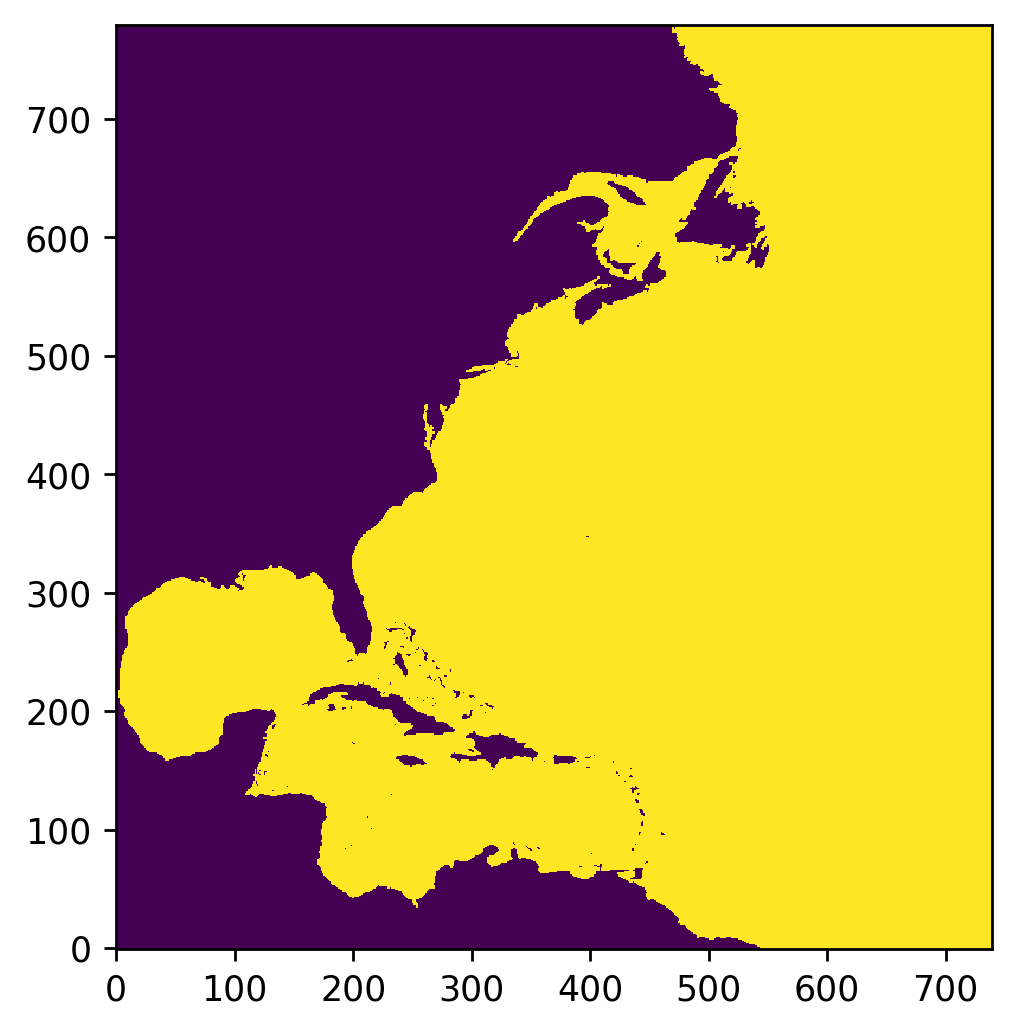

In [ ]:
# Display Mask

plt.figure(dpi=250)
plt.imshow(mask, origin='lower', interpolation='nearest')

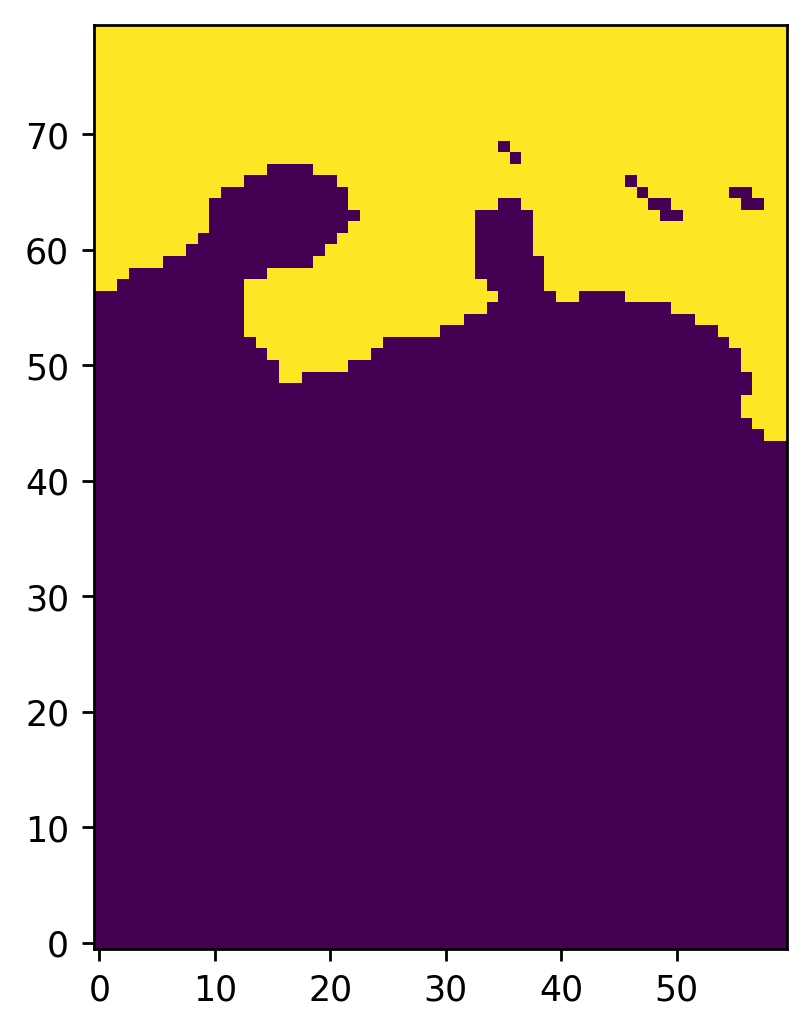

In [ ]:
# Display Mask

plt.figure(dpi=250)
plt.imshow(mask[20:100,300:360], origin='lower', interpolation='nearest')

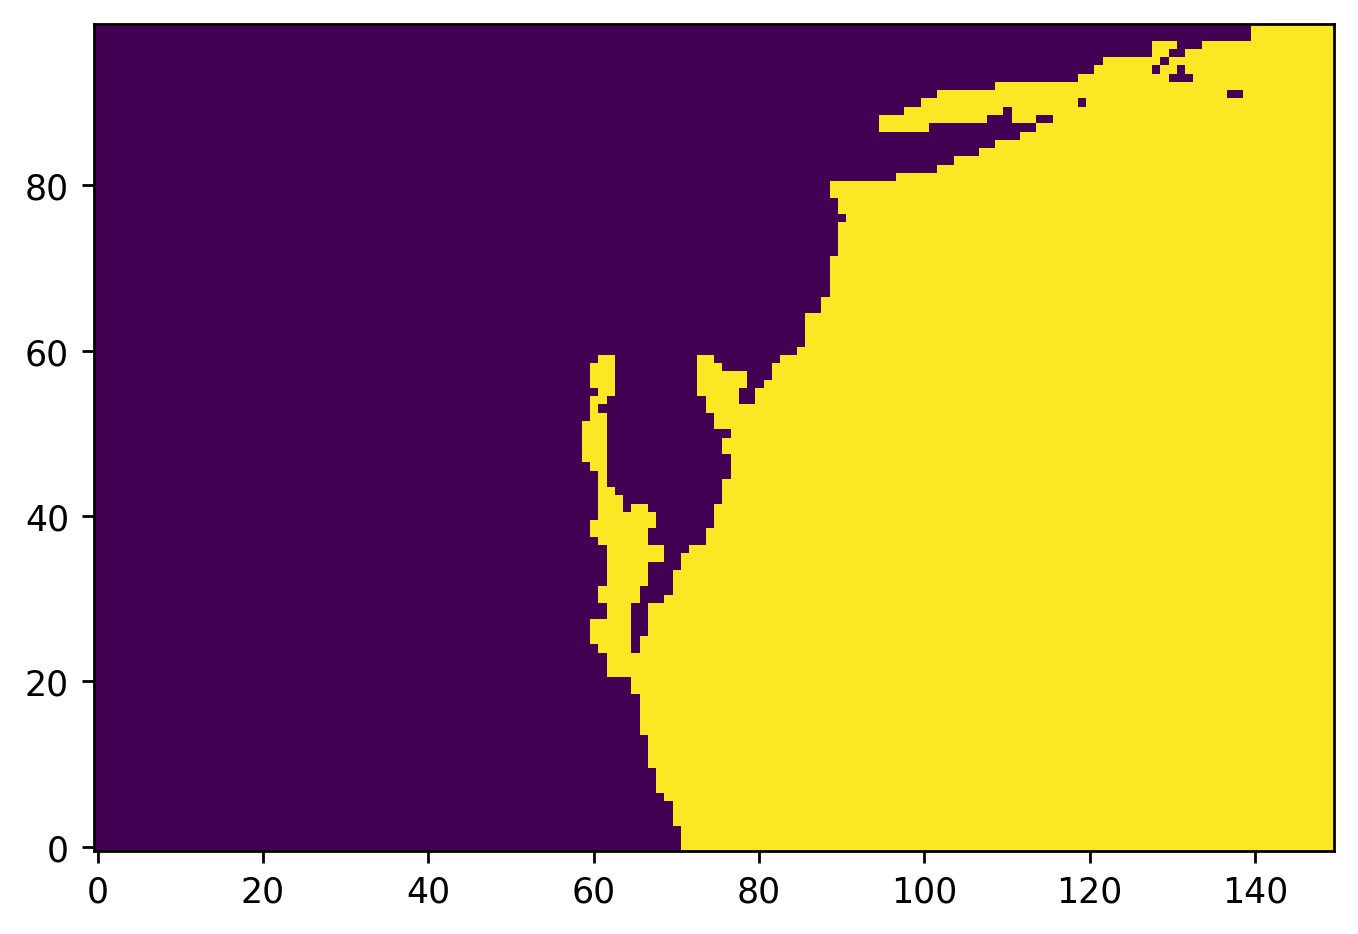

In [ ]:
# Display Mask

plt.figure(dpi=250)
plt.imshow(mask[400:500,200:350], origin='lower', interpolation='nearest')

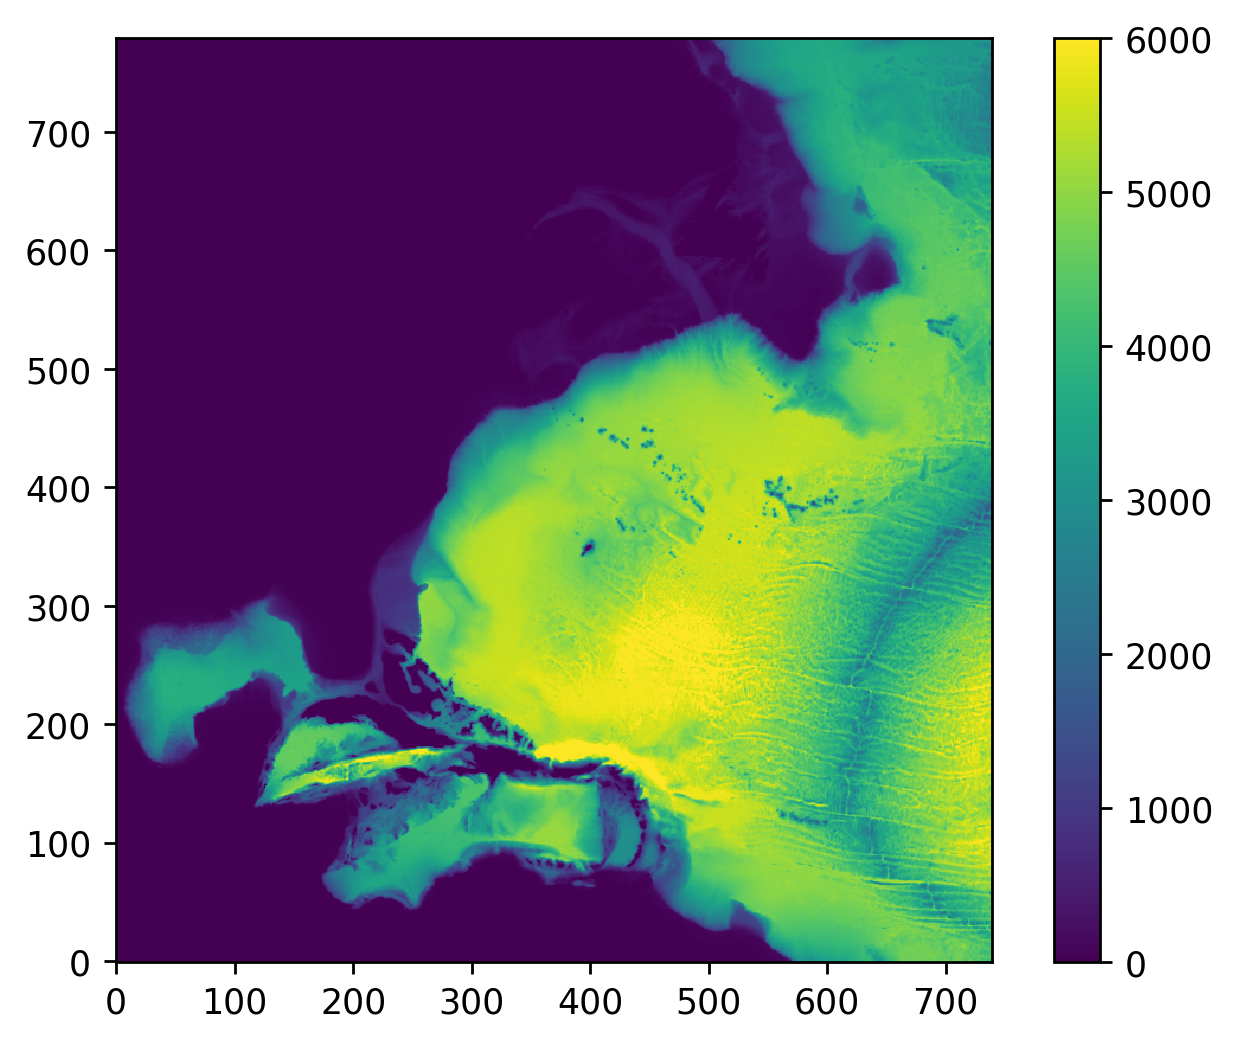

In [ ]:
# Display Topo

plt.figure(dpi=250)
plt.imshow(topo, origin='lower', interpolation='nearest')
plt.clim(0,6000)
plt.colorbar()

## Save Mask and Topo



In [ ]:
topo = topo.to_dataset(name='depth')
topo.to_netcdf('input_files/ocean_topo.nc')

In [ ]:
mask = mask.to_dataset(name='mask')
mask.to_netcdf('input_files/ocean_mask.nc')